# Density Estimation, Statistical Inference and Nonlinear Regression

Three experiments cover nonparametric classification, Gaussian maximum likelihood estimation, and Gaussian basis expansion with ridge regularization.

In [1]:
import numpy as np
import math

## Three-dimensional training samples

The three classes each contain ten explicitly defined samples. No external dataset is required for this experiment.

In [2]:
w1 = np.array([
    [0.28, 1.31, -6.2],
    [0.07, 0.58, -0.78],
    [1.54, 2.01, -1.63],
    [-0.44, 1.18, -4.32],
    [-0.81, 0.21, 5.73],
    [1.52, 3.16, 2.77],
    [2.20, 2.42, -0.19],
    [0.91, 1.94, 6.21],
    [0.65, 1.93, 4.38],
    [-0.26, 0.82, -0.96],
])

w2 = np.array([
    [0.011, 1.03, -0.21],
    [1.27, 1.28, 0.08],
    [0.13, 3.12, 0.16],
    [-0.21, 1.23, -0.11],
    [-2.18, 1.39, -0.19],
    [0.34, 1.96, -0.16],
    [-1.38, 0.94, 0.45],
    [-0.12, 0.82, 0.17],
    [-1.44, 2.31, 0.14],
    [0.26, 1.94, 0.08],
])

w3 = np.array([
    [1.36, 2.17, 0.14],
    [1.41, 1.45, -0.38],
    [1.22, 0.99, 0.69],
    [2.46, 2.19, 1.31],
    [0.68, 0.79, 0.87],
    [2.51, 3.22, 1.35],
    [2.60, 2.44, 0.92],
    [0.64, 0.13, 0.97],
    [0.85, 0.58, 0.99],
    [0.66, 0.51, 0.88],
])

# -----------------------------
# Test points
# -----------------------------
tests = np.array([
    [0.50, 1.00, 0.00],
    [0.31, 1.51, -0.50],
    [-0.30, 0.44, -0.10],
])

## Gaussian Parzen-window estimator

For class $k$, $\hat p(x\mid k)=[N_k(2\pi)^{d/2}h^d]^{-1}\sum_i\exp(-\|x-x_i\|^2/(2h^2))$. Equal class priors allow direct comparison of class-conditional densities. The bandwidth $h$ controls smoothing.

In [3]:
def parzen_density(X, x, h):
    N, d = X.shape
    d2 = np.sum((X - x) ** 2, axis=1)               # squared distances
    score = np.sum(np.exp(-d2 / (2 * h * h)))       # kernel sum
    const = 1.0 / (N * ((2 * math.pi) ** (d / 2)) * (h ** d))
    return const * score

def classify_parzen(x, h):
    d1 = parzen_density(w1, x, h)
    d2 = parzen_density(w2, x, h)
    d3 = parzen_density(w3, x, h)
    dens = np.array([d1, d2, d3])
    pred = int(np.argmax(dens) + 1)                 # class index in {1,2,3}
    return dens, pred

## Bandwidth comparison

Evaluate the three test points with $h=1$ and $h=0.1$. The selected class remains unchanged, even though the estimated densities differ by orders of magnitude.

In [9]:
for h in [1.0, 0.1]:
    print(f"\n=== Results for h = {h} ===")
    for i, x in enumerate(tests, start=1):
        dens, pred = classify_parzen(x, h)
        print(f"Test point {i}: x = {x}")
        print(f"  p_hat(x|w1) = {dens[0]:.12g}")
        print(f"  p_hat(x|w2) = {dens[1]:.12g}")
        print(f"  p_hat(x|w3) = {dens[2]:.12g}")
        print(f"  Predicted class: w{pred}")


=== Results for h = 1.0 ===
Test point 1: x = [0.5 1.  0. ]
  p_hat(x|w1) = 0.00799505387157
  p_hat(x|w2) = 0.0299104867364
  p_hat(x|w3) = 0.0239666615016
  Predicted class: w2
Test point 2: x = [ 0.31  1.51 -0.5 ]
  p_hat(x|w1) = 0.00974237173203
  p_hat(x|w2) = 0.0306544942489
  p_hat(x|w3) = 0.0130187552961
  Predicted class: w2
Test point 3: x = [-0.3   0.44 -0.1 ]
  p_hat(x|w1) = 0.00888327516884
  p_hat(x|w2) = 0.0240167425894
  p_hat(x|w3) = 0.0112425868233
  Predicted class: w2

=== Results for h = 0.1 ===
Test point 1: x = [0.5 1.  0. ]
  p_hat(x|w1) = 5.5713730924e-21
  p_hat(x|w2) = 4.29789661438e-06
  p_hat(x|w3) = 5.07961078285e-18
  Predicted class: w2
Test point 2: x = [ 0.31  1.51 -0.5 ]
  p_hat(x|w1) = 1.8229761644e-21
  p_hat(x|w2) = 7.62040346444e-07
  p_hat(x|w3) = 1.37103647407e-26
  Predicted class: w2
Test point 3: x = [-0.3   0.44 -0.1 ]
  p_hat(x|w1) = 2.30934148438e-13
  p_hat(x|w2) = 2.40202395604e-05
  p_hat(x|w3) = 6.75588842986e-41
  Predicted class: w2

### Bandwidth results
All three test points are assigned to class $\omega_2$ for both bandwidths. For $h=1$, its estimated densities are 0.0299105, 0.0306545 and 0.0240167; for $h=0.1$ they are $4.2979\times10^{-6}$, $7.6204\times10^{-7}$ and $2.4020\times10^{-5}$. A narrow kernel makes the estimate more local and can yield very small values away from training points. No labeled test accuracy is available for these three points.

## Maximum Likelihood Estimation for a Normal Distribution

Estimate the mean and variance of an independent normal sample, assess the likelihood surface, quantify uncertainty and test a hypothesized mean.

In [10]:
import re
import math
import numpy as np
import scipy.stats as st


### Data loader and negative log-likelihood

For variance $v>0$, the normal negative log-likelihood is $\ell_-(\mu,v)=\tfrac n2\log(2\pi v)+\frac{1}{2v}\sum_i(x_i-\mu)^2$. Invalid nonpositive variances receive infinite loss.

In [11]:
def load_numbers_any_whitespace(path: str) -> np.ndarray:
    """
    Load all floating-point numbers from a text file, regardless of line breaks / variable columns.
    """
    with open(path, "r", encoding="utf-8") as f:
        text = f.read()
    tokens = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", text)
    return np.array([float(t) for t in tokens], dtype=float)

def nll_normal(mu: float, sigma2: float, x: np.ndarray) -> float:
    """
    Negative log-likelihood for Normal(mu, sigma2) for i.i.d. sample x.
    """
    if sigma2 <= 0:
        return float("inf")
    n = len(x)
    return 0.5 * n * math.log(2 * math.pi * sigma2) + 0.5 * np.sum((x - mu) ** 2) / sigma2

### Load the normal sample

Read the numerical observations from `../datasets/normal_distribution/normal.data.txt`; the saved output contains 200 observations.

In [12]:
path = "../datasets/normal_distribution/normal.data.txt"
x = load_numbers_any_whitespace(path)
n = len(x)

print(f"n = {n}")

n = 200


### Closed-form MLE and numerical verification

Differentiating the negative log-likelihood gives $\hat\mu=\bar x$ and $\hat v=n^{-1}\sum_i(x_i-\bar x)^2$. Check these estimates using separate one-dimensional grid scans with the other parameter fixed.

In [13]:
mu_hat = float(np.mean(x))
sigma2_hat = float(np.mean((x - mu_hat) ** 2))  # MLE uses 1/n (not 1/(n-1))

print("\n(a) MLEs (closed-form):")
print(f"mu_hat     = {mu_hat:.6f}")
print(f"sigma2_hat = {sigma2_hat:.6f}")

# Numerical check: show that these minimize NLL by scanning a local grid
mu_grid = np.linspace(mu_hat - 5, mu_hat + 5, 401)
sig2_grid = np.linspace(max(1e-6, sigma2_hat * 0.3), sigma2_hat * 2.0, 401)

# Fix sigma2 at sigma2_hat and scan mu
nll_mu_scan = np.array([nll_normal(m, sigma2_hat, x) for m in mu_grid])
mu_min_scan = mu_grid[np.argmin(nll_mu_scan)]

# Fix mu at mu_hat and scan sigma2
nll_sig2_scan = np.array([nll_normal(mu_hat, s2, x) for s2 in sig2_grid])
sig2_min_scan = sig2_grid[np.argmin(nll_sig2_scan)]

print("\n(a) Numerical check (grid scan):")
print(f"mu minimizing NLL (scan, sigma2 fixed)     ≈ {mu_min_scan:.6f}")
print(f"sigma2 minimizing NLL (scan, mu fixed)     ≈ {sig2_min_scan:.6f}")



(a) MLEs (closed-form):
mu_hat     = 100.480500
sigma2_hat = 216.318470

(a) Numerical check (grid scan):
mu minimizing NLL (scan, sigma2 fixed)     ≈ 100.480500
sigma2 minimizing NLL (scan, mu fixed)     ≈ 216.588868


### Negative log-likelihood comparison

Compare the fitted parameters with a shifted pair. The grid and shifted-point comparison provide numerical support for the analytical solution.

In [14]:
nll_at_hat = nll_normal(mu_hat, sigma2_hat, x)
nll_at_shift = nll_normal(mu_hat + 1.0, sigma2_hat * 1.1, x)

print("\n(b) NLL comparison:")
print(f"NLL at (mu_hat, sigma2_hat) = {nll_at_hat:.6f}")
print(f"NLL at shifted params       = {nll_at_shift:.6f}")
print("Smaller is better; should be minimized near (mu_hat, sigma2_hat).")


(b) NLL comparison:
NLL at (mu_hat, sigma2_hat) = 821.462879
NLL at shifted params       = 822.323243
Smaller is better; should be minimized near (mu_hat, sigma2_hat).


### Fisher-information covariance

For parameters $(\mu,v)$, the estimated asymptotic covariance is $\operatorname{diag}(\hat v/n,2\hat v^2/n)$. The mean and variance estimates are asymptotically uncorrelated.

In [15]:
var_mu = sigma2_hat / n
var_sigma2 = 2.0 * (sigma2_hat ** 2) / n
cov_asym = np.array([[var_mu, 0.0],
                     [0.0,  var_sigma2]])

print("\n(c) Estimated asymptotic covariance matrix (plug-in):")
print(cov_asym)


(c) Estimated asymptotic covariance matrix (plug-in):
[[  1.08159235   0.        ]
 [  0.         467.93680355]]


### Alternative variance plug-in

Use the unbiased sample variance with denominator $n-1$ instead of the MLE to construct an alternative covariance estimate. This is a comparison of plug-in estimators, not proof of superior covariance accuracy.

In [16]:
s2_unbiased = float(np.var(x, ddof=1))  # unbiased sample variance
cov_asym_unbiasedplug = np.array([[s2_unbiased / n, 0.0],
                                  [0.0, 2.0 * (s2_unbiased ** 2) / n]])

print("\n(d) Alternative plug-in using unbiased variance s^2 (optional comparison):")
print(f"s^2 (unbiased) = {s2_unbiased:.6f}")
print(cov_asym_unbiasedplug)


(d) Alternative plug-in using unbiased variance s^2 (optional comparison):
s^2 (unbiased) = 217.405497
[[  1.08702749   0.        ]
 [  0.         472.65150229]]


### Confidence interval for variance

The implementation uses a chi-square pivot with `df=n`. Because the mean is estimated from the same sample, the exact normal-theory pivot actually has $n-1$ degrees of freedom. The displayed interval is therefore an approximation using the implemented convention.

In [17]:
alpha = 0.05
chi2_lo = st.chi2.ppf(alpha / 2.0, df=n)
chi2_hi = st.chi2.ppf(1.0 - alpha / 2.0, df=n)
ci_sigma2 = (n * sigma2_hat / chi2_hi, n * sigma2_hat / chi2_lo)

print("\n(e) 95% CI for sigma^2 (chi-square, df=n):")
print(f"CI_sigma2 = ({ci_sigma2[0]:.6f}, {ci_sigma2[1]:.6f})")


(e) 95% CI for sigma^2 (chi-square, df=n):
CI_sigma2 = (179.474287, 265.865116)


### Hypothesis tests for the mean

Test $H_0:\mu=103$ using the asymptotic Z statistic, likelihood-ratio statistic and Wald statistic. The squared Z statistic equals the Wald statistic here because they use the same plug-in variance.

In [18]:
mu0 = 103.0

# Z-test
Z = (mu_hat - mu0) / math.sqrt(sigma2_hat / n)
pZ = 2.0 * (1.0 - st.norm.cdf(abs(Z)))

# LR test with sigma2 profiled out:
# ell(mu, sigma2_MLE(mu)) => LR = n * log(SSE0/SSE1)
SSE1 = float(np.sum((x - mu_hat) ** 2))
SSE0 = float(np.sum((x - mu0) ** 2))
LR = n * math.log(SSE0 / SSE1)
pLR = 1.0 - st.chi2.cdf(LR, df=1)

# Wald
Wald = (mu_hat - mu0) ** 2 / (sigma2_hat / n)
pW = 1.0 - st.chi2.cdf(Wald, df=1)

print("\n(f) Testing H0: mu = 103")
print(f"Z-test:   Z = {Z:.6f},    p-value = {pZ:.6f}")
print(f"LR test:  LR = {LR:.6f},  p-value = {pLR:.6f}")
print(f"Wald:     W = {Wald:.6f}, p-value = {pW:.6f}")


(f) Testing H0: mu = 103
Z-test:   Z = -2.422605,    p-value = 0.015410
LR test:  LR = 5.784549,  p-value = 0.016168
Wald:     W = 5.869014, p-value = 0.015410


### Coefficient of variation and delta method

For positive mean, $g(\mu,v)=\sqrt v/\mu$. Multiplying observations by a positive constant leaves the ratio unchanged. Its gradient is $(-\sqrt v/\mu^2,1/(2\mu\sqrt v))^T$; the delta-method variance is $\nabla g^T\widehat{\operatorname{Cov}}\nabla g$.

In [19]:
cv_hat = math.sqrt(sigma2_hat) / mu_hat

dg_dmu = -math.sqrt(sigma2_hat) / (mu_hat ** 2)
dg_dsig2 = 1.0 / (2.0 * mu_hat * math.sqrt(sigma2_hat))
grad = np.array([dg_dmu, dg_dsig2])

var_cv = float(grad.T @ cov_asym @ grad)
se_cv = math.sqrt(var_cv)
z975 = st.norm.ppf(0.975)
ci_cv = (cv_hat - z975 * se_cv, cv_hat + z975 * se_cv)

print("\n(g) Coefficient of Variation (CV)")
print(f"CV_hat = {cv_hat:.6f}")
print(f"Delta-method SE(CV_hat) = {se_cv:.6f}")
print(f"95% CI for CV (delta) = ({ci_cv[0]:.6f}, {ci_cv[1]:.6f})")


(g) Coefficient of Variation (CV)
CV_hat = 0.146374
Delta-method SE(CV_hat) = 0.007474
95% CI for CV (delta) = (0.131726, 0.161023)


### Statistical results
The estimates are $\hat\mu=100.4805$ and $\hat v=216.318470$. The minimum negative log-likelihood is 821.462879, below 822.323243 at the shifted pair. The estimated covariance diagonal is (1.08159235, 467.93680355); the unbiased-variance alternative is (1.08702749, 472.65150229).

| Test | Statistic | p-value |
|---|---:|---:|
| Z | -2.422605 | 0.015410 |
| Likelihood ratio | 5.784549 | 0.016168 |
| Wald | 5.869014 | 0.015410 |

All three tests reject the hypothesized mean of 103 at the 5% level under their asymptotic assumptions. The implemented variance interval is (179.474287, 265.865116); see the degrees-of-freedom caveat above. The CV estimate is 0.146374 (SE 0.007474), with a delta-method 95% interval of (0.131726, 0.161023).

## Nonlinear Regression with Gaussian Basis Functions

Use a fixed nonlinear feature mapping and fit linear coefficients by ridge regression.

### Reproducibility

Initialize the NumPy random generator with seed 7.

In [20]:
np.random.seed(7)

### Synthetic observations

Generate 25 independent inputs uniformly on $[0,1]$, with $y=\operatorname{sinc}(3x)+\epsilon$ and $\epsilon\sim\mathcal N(0,0.01)$. NumPy uses the normalized sinc convention.

In [21]:
def true_function(x):
    x = np.asarray(x)
    return np.sinc(3 * x)

def generate_dataset(n=25, noise_var=0.01):
    x = np.random.uniform(0.0, 1.0, size=n)
    eps = np.random.normal(0.0, np.sqrt(noise_var), size=n)
    y = true_function(x) + eps
    return x, y

### Gaussian radial basis expansion

Use 21 centers evenly spaced on $[0,1]$, standard deviation 0.04 and a constant bias column. The resulting design matrix has 22 columns.

In [22]:
def design_matrix(x, means, sigma):
    x = np.asarray(x).reshape(-1, 1)          # (n,1)
    means = np.asarray(means).reshape(1, -1)  # (1,d)
    Phi = np.exp(- (x - means) ** 2 / (2 * sigma ** 2))  # (n,d)
    H = np.concatenate([np.ones((len(x), 1)), Phi], axis=1)  # add bias column
    return H

### Ridge regression solver

Solve $(H^TH+\lambda R)\hat\beta=H^Ty$, where $R=\operatorname{diag}(0,1,\ldots,1)$ leaves the intercept unpenalized. Use a linear system solver rather than explicitly inverting the matrix.

In [23]:
def ridge_fit(H, y, lam, penalize_bias=False):
    d = H.shape[1]
    R = np.eye(d)
    if not penalize_bias:
        R[0, 0] = 0.0
    beta = np.linalg.solve(H.T @ H + lam * R, H.T @ y)
    return beta

def predict(x, beta, means, sigma):
    return design_matrix(x, means, sigma) @ beta

### Comparing regularization strengths

For $\lambda\in\{0.001,0.05,5\}$, plot the true function, the fit to a single dataset and the average fit obtained from 100 independently generated datasets.

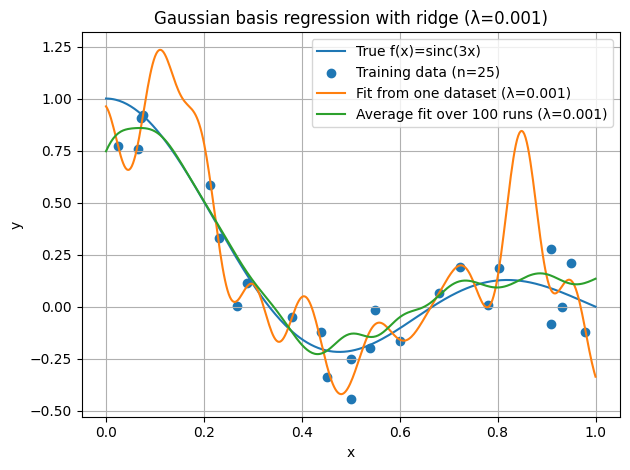

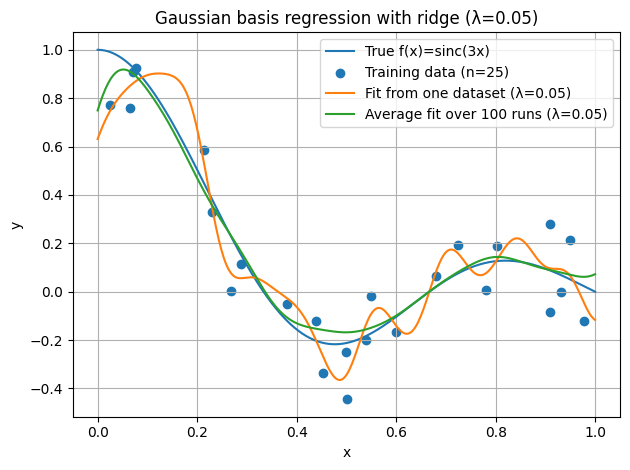

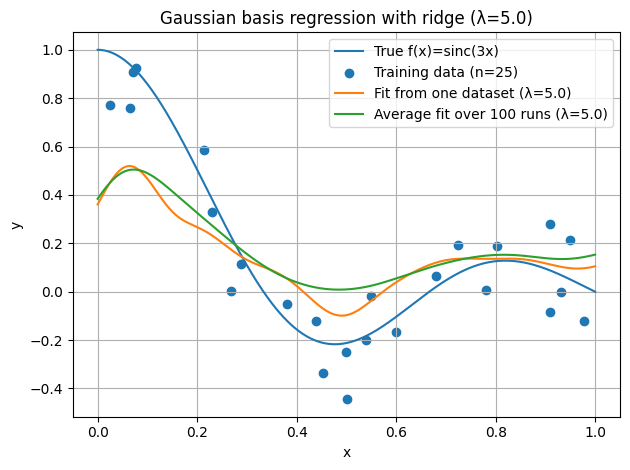

In [24]:
n = 25
d = 21
means = np.linspace(0.0, 1.0, d)  # mu_j
sigma = 0.04
lams_fixed = [0.001, 0.05, 5.0]

# One dataset (single training vector)
x_train, y_train = generate_dataset(n=n, noise_var=0.01)
H_train = design_matrix(x_train, means, sigma)

# Grid for plotting
x_grid = np.linspace(0.0, 1.0, 400)
f_true_grid = true_function(x_grid)

# Repeat experiment 100 times and average betas
R = 100
beta_avgs = {}
for lam in lams_fixed:
    betas = []
    for _ in range(R):
        xr, yr = generate_dataset(n=n, noise_var=0.01)
        Hr = design_matrix(xr, means, sigma)
        betas.append(ridge_fit(Hr, yr, lam, penalize_bias=False))
    betas = np.vstack(betas)
    beta_avgs[lam] = betas.mean(axis=0)

# Produce 3 plots (one per lambda)
for lam in lams_fixed:
    beta_single = ridge_fit(H_train, y_train, lam, penalize_bias=False)

    y_fit_single = predict(x_grid, beta_single, means, sigma)
    y_fit_avg = predict(x_grid, beta_avgs[lam], means, sigma)

    plt.figure()
    plt.plot(x_grid, f_true_grid, label="True f(x)=sinc(3x)")
    plt.scatter(x_train, y_train, label="Training data (n=25)", marker="o")
    plt.plot(x_grid, y_fit_single, label=f"Fit from one dataset (λ={lam})")
    plt.plot(x_grid, y_fit_avg, label=f"Average fit over 100 runs (λ={lam})")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Gaussian basis regression with ridge (λ={lam})")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"q12_fit_lambda_{str(lam).replace('.','p')}.png", dpi=200)
    plt.show()

### Monte Carlo approximation error

For each value on an exponential regularization grid, repeat data generation and fitting 100 times. Evaluate mean squared approximation error relative to the noiseless function on 100 evenly spaced points. This estimates error for the simulated setting, not performance on an external test dataset.

Best lambda (grid) = 0.24659696394160596
Min average error  = 0.011645901005348801


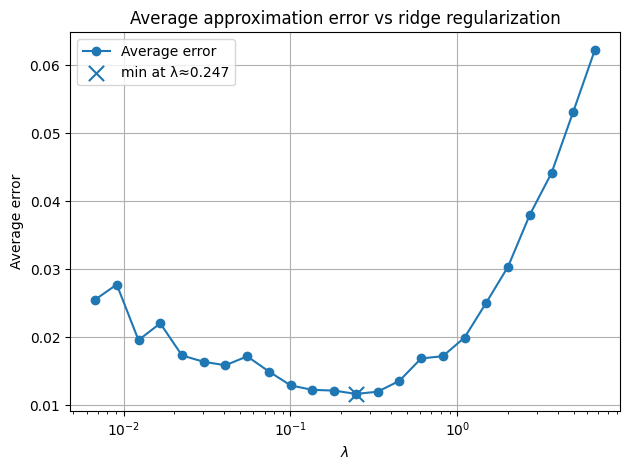

In [25]:
lam_grid = np.exp(np.arange(-5.0, 2.0001, 0.3))
m = 100
z = np.linspace(0.0, 1.0, m)
f_z = true_function(z)

avg_err = []
for lam in lam_grid:
    errs = []
    for _ in range(R):
        xr, yr = generate_dataset(n=n, noise_var=0.01)
        Hr = design_matrix(xr, means, sigma)
        beta = ridge_fit(Hr, yr, lam, penalize_bias=False)
        fhat_z = predict(z, beta, means, sigma)
        errs.append(np.mean((f_z - fhat_z) ** 2))
    avg_err.append(np.mean(errs))
avg_err = np.array(avg_err)

best_idx = int(np.argmin(avg_err))
best_lam = float(lam_grid[best_idx])
best_err = float(avg_err[best_idx])

print("Best lambda (grid) =", best_lam)
print("Min average error  =", best_err)

plt.figure()
plt.plot(lam_grid, avg_err, marker="o", label="Average error")
plt.xscale("log")
plt.scatter([best_lam], [best_err], marker="x", s=120, label=f"min at λ≈{best_lam:.3g}")
plt.xlabel(r"$\lambda$")
plt.ylabel("Average error")
plt.title("Average approximation error vs ridge regularization")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("q12_avg_error_vs_lambda.png", dpi=200)
plt.show()

### Regression results and conclusions
Small regularization permits greater sensitivity to sampled noise; strong regularization shrinks the coefficients and increases approximation bias. The minimum average approximation error on the evaluated grid is **0.0116459010** at $\lambda=0.2465969639$. This intermediate optimum illustrates the bias–variance tradeoff for the chosen basis and simulated data. It is not a universal optimal regularization parameter. See [analysis notes](docs/density_estimation_and_regression.md).